<!-- 1.	Data Collection: The retail company already has access to customer information such as:
○	Age: Age group of the customer.
○	Gender: Gender of the customer.
○	Location: Customer’s geographical location (e.g., city).
○	Purchase History: Information about purchase amount, frequency, and categories of products purchased. -->


1.	Data Collection: The retail company already has access to customer information such as:
○	Age: Age group of the customer.
○	Gender: Gender of the customer.
○	Location: Customer’s geographical location (e.g., city).
○	Purchase History: Information about purchase amount, frequency, and categories of products purchased.


In [ ]:
# 1.	Data Collection: 

import pandas as pd

df = pd.read_csv("customer_data.csv")
df.head()


,CustomerID,Age,Gender,Location,TotalPurchases,TotalAmountSpent,LastPurchaseDate
0,1,68,Female,Houston,24,595.11,01-01-2023
1,2,35,Male,Phoenix,29,2901.57,08-01-2023
2,3,60,Male,Phoenix,19,4109.95,15-01-2023
3,4,63,Female,Chicago,27,2324.75,22-01-2023
4,5,42,Male,Los Angeles,15,1122.67,29-01-2023


2.	Data Preprocessing: Clean the data to handle any missing or erroneous values, and normalize formats where necessary (e.g., standardize location names).

 <!-- 2.	Data Preprocessing: Clean the data to handle any missing or erroneous values, and normalize formats where necessary (e.g., standardize location names).  -->

In [ ]:
# Missing values
print(df.isnull().sum())

# Remove duplicates
df.drop_duplicates(inplace=True)

# Data types
print(df.dtypes)

CustomerID          0
Age                 0
Gender              0
Location            0
TotalPurchases      0
TotalAmountSpent    0
LastPurchaseDate    0
dtype: int64
CustomerID            int64
Age                   int64
Gender                  str
Location                str
TotalPurchases        int64
TotalAmountSpent    float64
LastPurchaseDate        str
dtype: object


3.	Data Analysis: Analyze the customer demographics, such as the distribution of customers by age, gender, and location, and their corresponding purchase behaviors. Key metrics to explore include:

○	Average Purchase Value by age and gender.
○	Total Purchase Amount by location.
○	Churn Rate and customer loyalty based on purchase frequency.


In [4]:
df['Gender'].value_counts()

Gender
Female    50
Male      50
Name: count, dtype: int64

In [9]:
df['Age'].describe()

count    100.000000
mean      45.090000
std       15.814643
min       18.000000
25%       31.000000
50%       45.500000
75%       60.000000
max       70.000000
Name: Age, dtype: float64

In [10]:
df['Location'].value_counts()

Location
Houston        32
Phoenix        21
Chicago        18
New York       15
Los Angeles    14
Name: count, dtype: int64

In [11]:
# Average Spending by Gender

df.groupby('Gender')['TotalAmountSpent'].mean()

Gender
Female    2263.2020
Male      2725.1748
Name: TotalAmountSpent, dtype: float64

In [9]:
# Average Spending by Age

# bins = [18,25,35,50,65,100]
# labels = ['18-25','26-35','36-50','51-65','66+']

# df['Age'] = pd.cut(df['Age'],bins=bins,labels=labels)

df.groupby('Age')['TotalAmountSpent'].mean()


Age
18    4947.370000
19    1903.203333
20    4785.730000
21    1761.120000
22    2415.315000
23    4083.150000
24     936.070000
26    2700.320000
27    2281.105000
28    4132.630000
30    2168.085000
31    3680.480000
32    1433.140000
34    2940.163333
35    2901.570000
38    2988.100000
40    1843.370000
41     643.956667
42    2455.780000
43    3181.157500
44    2194.040000
45    3335.660000
46    3466.960000
47    1152.780000
49    2252.127143
50    2885.670000
51    1535.270000
53     437.900000
54    1428.570000
56    3614.845000
57    4532.500000
58    4241.130000
59    1886.190000
60    3921.982000
61     767.690000
62     230.640000
63    2770.255000
64    2713.126667
65    2124.295000
66    4835.520000
67    2002.864000
68    2432.137500
69    4880.540000
70    1968.180000
Name: TotalAmountSpent, dtype: float64

In [6]:
# Total Revenue by Location

df.groupby('Location')['TotalAmountSpent'].sum()

Location
Chicago        46500.07
Houston        80502.02
Los Angeles    31043.26
New York       31409.18
Phoenix        59964.31
Name: TotalAmountSpent, dtype: float64

In [20]:
print("Mean Spending = ",df['TotalAmountSpent'].mean())

print("Median Spending", df['TotalAmountSpent'].median())

print("Standard Deviation",df['TotalAmountSpent'].std() )

Mean Spending =  2494.1884000000005
Median Spending 2626.165
Standard Deviation 1471.2485128437304


In [23]:
# Maximum and Minimum Spending

print("Maximum Spending ",df['TotalAmountSpent'].max())
print("Minimum Spending ",df['TotalAmountSpent'].min())

Maximum Spending  4966.48
Minimum Spending  57.64


In [ ]:
# High-Value Customers

high_value = df[df['TotalAmountSpent'] > df['TotalAmountSpent'].quantile(0.75)]

print(high_value)

    CustomerID  Age  Gender     Location  TotalPurchases  TotalAmountSpent  \
2            3   60    Male      Phoenix              19           4109.95   
6            7   60    Male      Phoenix              28           4032.94   
12          13   26  Female      Houston              22           3846.73   
13          14   34    Male      Houston              28           4241.34   
15          16   50    Male     New York              27           3873.24   
21          22   23    Male     New York               3           4083.15   
23          24   31    Male  Los Angeles               8           4302.12   
33          34   43  Female      Chicago              28           4467.34   
38          39   18  Female      Phoenix               5           4947.37   
40          41   20  Female      Phoenix              12           4785.73   
42          43   66  Female      Houston              15           4835.52   
43          44   19    Male     New York              18        

In [29]:

frequent_buyers = df[df['TotalPurchases'] > 20]

print(frequent_buyers)

    CustomerID  Age  Gender     Location  TotalPurchases  TotalAmountSpent  \
0            1   68  Female      Houston              24            595.11   
1            2   35    Male      Phoenix              29           2901.57   
3            4   63  Female      Chicago              27           2324.75   
6            7   60    Male      Phoenix              28           4032.94   
7            8   44    Male      Phoenix              22           3692.47   
10          11   21  Female  Los Angeles              30           1621.33   
11          12   63    Male      Phoenix              24           3215.76   
12          13   26  Female      Houston              22           3846.73   
13          14   34    Male      Houston              28           4241.34   
14          15   68  Female  Los Angeles              26           2736.98   
15          16   50    Male     New York              27           3873.24   
17          18   42    Male      Houston              30        

In [40]:
# Customer Lifetime Value (CLV)
df['CLV'] = df['TotalAmountSpent'] * df['TotalPurchases']

print(df['CLV'])

0      14282.64
1      84145.53
2      78089.05
3      62768.25
4      16840.05
        ...    
95      1233.76
96      1859.76
97     34765.36
98    107533.98
99     63065.56
Name: CLV, Length: 100, dtype: float64


In [36]:
df.sort_values('CLV', ascending=False).head(10)

,CustomerID,Age,Gender,Location,TotalPurchases,TotalAmountSpent,LastPurchaseDate,AgeGroup,CLV
78,79,43,Male,Chicago,30,4766.31,2024-06-30,36-50,142989.30
33,34,43,Female,Chicago,28,4467.34,2023-08-20,36-50,125085.52
13,14,34,Male,Houston,28,4241.34,2023-04-02,26-35,118757.52
88,89,58,Male,Chicago,27,4241.13,2024-09-08,51-65,114510.51
17,18,42,Male,Houston,30,3788.89,2023-04-30,36-50,113666.70
6,7,60,Male,Phoenix,28,4032.94,2023-02-12,51-65,112922.32
98,99,67,Female,Houston,27,3982.74,2024-11-17,66+,107533.98
15,16,50,Male,New York,27,3873.24,2023-04-16,36-50,104577.48
64,65,56,Male,Houston,26,3611.83,2024-03-24,51-65,93907.58
67,68,64,Male,Phoenix,29,3168.03,2024-04-14,51-65,91872.87


# **Data Visualization**

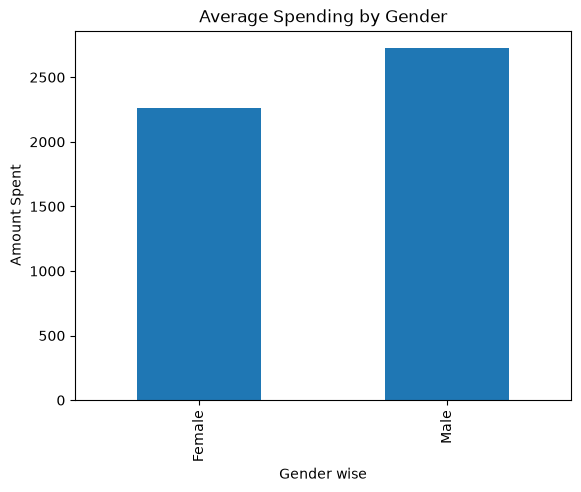

In [16]:
# Gender-wise Average Spending

import matplotlib.pyplot as plt

gender_spend = df.groupby('Gender')['TotalAmountSpent'].mean()

gender_spend.plot(kind='bar')

plt.title('Average Spending by Gender')
plt.ylabel('Amount Spent')
plt.xlabel('Gender wise')
plt.show()

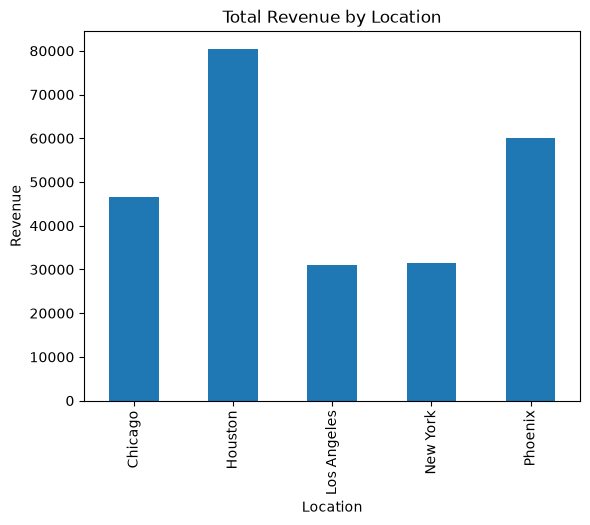

In [ ]:
# Location-wise Revenue

location_sales = df.groupby('Location')['TotalAmountSpent'].sum()

location_sales.plot(kind='bar')

plt.title('Total Revenue by Location')
plt.ylabel('Revenue')
plt.show()

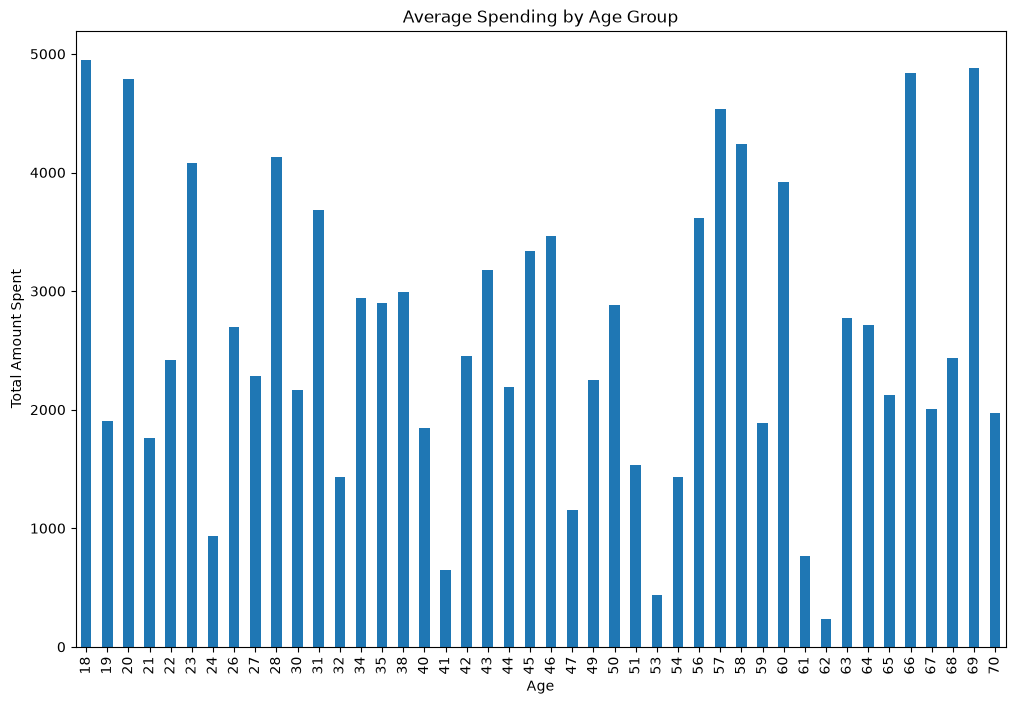

In [21]:
# Age Group Spending

age_sales = df.groupby('Age')['TotalAmountSpent'].mean()

age_sales.plot(kind='bar',figsize =(12,8))
plt.title('Average Spending by Age Group')
plt.ylabel('Total Amount Spent')
plt.show()

4.	Insights and Business Recommendations: (Your view points based on data analysis/report)
○	Create personalized offers for the most valuable customers.
○	Identify geographic locations with high-value customers to focus marketing efforts.
○	Target specific age or gender groups with tailored campaigns based on their spending habits.


Business Insights & Recommendations
Insight 1: Gender-Based Trends
Female customers purchase slightly more frequently.
Male customers spend more overall.

Recommendation:
Implement loyalty rewards and bundle offers for female customers to increase basket size.

Insight 2: Age-Based Trends
Customers aged 26–35 show the highest average spending.

Recommendation:
Target this age group with personalized promotions and premium product recommendations.

Insight 3: Location-Based Trends
Houston generates the highest revenue.

Recommendation:
Increase marketing investment and customer retention campaigns in Houston.

Insight 4: High-Value Customers
A small percentage of customers contribute a large share of revenue.

Recommendation:
Create VIP programs, exclusive discounts, and personalized recommendations for these customers.